# Свёрточные сети. BatchNorm и Dropout

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "06_cnn_regularization"
OUT.mkdir(exist_ok=True, parents=True)

## Ручная свёртка, размеры и baseline

MNIST: 2400 train, 600 validation, 600 test. Вход [B, 1, 28, 28]. Метрики — accuracy и macro-F1. В CNN два свёрточных блока. Размер выхода свёртки: floor((n + 2p − k)/s) + 1.

Ручная операция cross-correlation:
 [[-6. -6. -6.]
 [-6. -6. -6.]
 [-6. -6. -6.]]
Размеры padding=0: torch.Size([1, 1, 3, 3]) padding=1: torch.Size([1, 1, 5, 5])
MLP validation: {'accuracy': 0.91, 'macro_f1': 0.9070925545892236} параметров: 50890


CNN validation: {'accuracy': 0.8983333333333333, 'macro_f1': 0.8949752621921638} параметров: 2698


,layer,output
0,"Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1)...","(2, 8, 28, 28)"
1,ReLU(),"(2, 8, 28, 28)"
2,"MaxPool2d(kernel_size=2, stride=2, padding=0, ...","(2, 8, 14, 14)"
3,"Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1...","(2, 16, 14, 14)"
4,ReLU(),"(2, 16, 14, 14)"
5,"MaxPool2d(kernel_size=2, stride=2, padding=0, ...","(2, 16, 7, 7)"


Первый Conv2d, вручную: 80


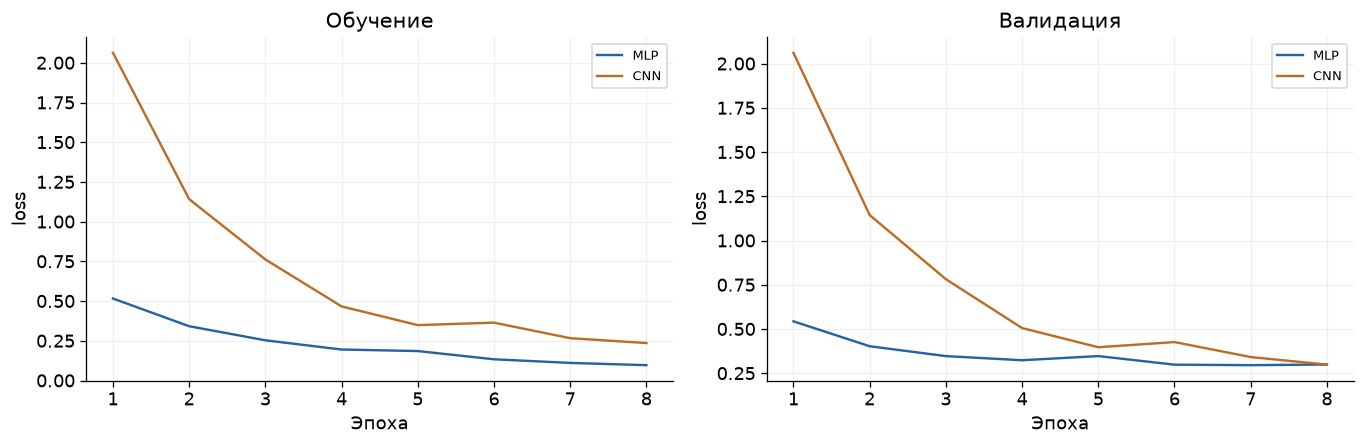

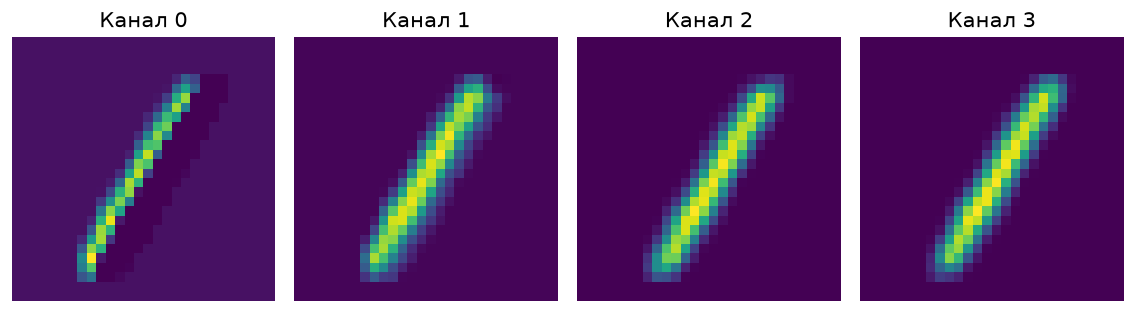

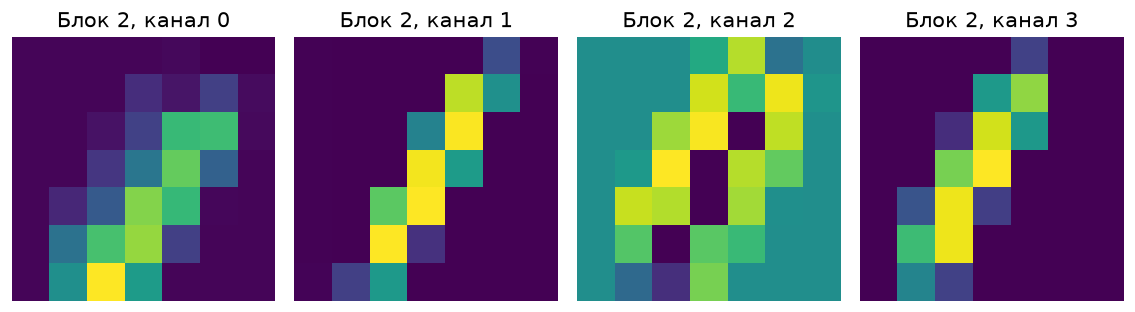

Ранние карты реагируют на локальные штрихи и границы; последующие объединяют несколько локальных структур. В PyTorch Conv2d вычисляет cross-correlation, поэтому ручная проверка использует ядро без отражения.

In [2]:
import torch.nn.functional as F
from torchvision.ops import deform_conv2d

train, val, test = mnist()
a = np.arange(25, dtype="float32").reshape(5, 5)
k = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype="float32")
manual = np.array(
    [[np.sum(a[i : i + 3, j : j + 3] * k) for j in range(3)] for i in range(3)]
)
conv = F.conv2d(tensor(a)[None, None], tensor(k)[None, None])
assert np.allclose(manual, conv.numpy()[0, 0])
print("Ручная операция cross-correlation:\n", manual)
print(
    "Размеры padding=0:",
    conv.shape,
    "padding=1:",
    F.conv2d(tensor(a)[None, None], tensor(k)[None, None], padding=1).shape,
)
seed_all()
baseline = MLP(784, 10, (64,))
baseline, bh, bt = fit(baseline, train, val, epochs=8, lr=0.003)
print(
    "MLP validation:", classify(baseline, val)[0], "параметров:", count_params(baseline)
)
seed_all()
cnn = CNN()
cnn, ch, ct = fit(cnn, train, val, epochs=8, lr=0.003)
print("CNN validation:", classify(cnn, val)[0], "параметров:", count_params(cnn))
xb = train[0][:2]
shape_rows = []
for i, layer in enumerate(cnn.features):
    xb = layer(xb)
    shape_rows.append({"layer": str(layer), "output": str(tuple(xb.shape))})
table(shape_rows, OUT, "dimensions")
print("Первый Conv2d, вручную:", 8 * (1 * 3 * 3 + 1))
histories({"MLP": bh, "CNN": ch}, OUT, "baseline_curves")
acts = cnn.features[:2](test[0][:1]).detach().numpy()[0]
fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for i, a in enumerate(ax):
    a.imshow(acts[i], cmap="viridis")
    a.set_title(f"Канал {i}")
    a.axis("off")
showfig("first_feature_maps", OUT)
acts2 = cnn.features(test[0][:1]).detach().numpy()[0]
fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for i, a in enumerate(ax):
    a.imshow(acts2[i], cmap="viridis")
    a.set_title(f"Блок 2, канал {i}")
    a.axis("off")
showfig("second_feature_maps", OUT)
note(
    "Ранние карты реагируют на локальные штрихи и границы; последующие объединяют несколько локальных структур. В PyTorch Conv2d вычисляет cross-correlation, поэтому ручная проверка использует ядро без отражения."
)

## Padding, stride, pooling и устойчивость

Меняю по одному параметру CNN и проверяю качество на чистых и зашумлённых изображениях.

,configuration,accuracy,macro_f1,seconds,parameters
0,standard,0.87000,0.86736,0.98359,2698
1,padding0,0.88167,0.88145,0.87414,2698
2,stride2,0.86500,0.86378,1.11738,2698
3,average_pool,0.80167,0.79431,0.95028,2698


CNN clean: {'accuracy': 0.93, 'macro_f1': 0.9295509289420556} noise σ=.2: {'accuracy': 0.755, 'macro_f1': 0.74963808880458}


,index,true,predicted,confidence,probability_margin,analysis
0,47,4,0,0.47174,0.10827,Ошибка при близких вероятностях классов
1,50,7,2,0.92757,0.87445,Уверенная ошибка: проверить неоднозначность пр...
2,51,9,4,0.47398,0.22991,Ошибка при близких вероятностях классов
3,86,5,9,0.68914,0.43054,Уверенная ошибка: проверить неоднозначность пр...
4,97,8,6,0.56000,0.29709,Уверенная ошибка: проверить неоднозначность пр...
5,98,9,0,0.89628,0.83948,Уверенная ошибка: проверить неоднозначность пр...
6,99,1,6,0.95837,0.94016,Уверенная ошибка: проверить неоднозначность пр...
7,100,7,8,0.30550,0.04342,Ошибка при близких вероятностях классов
8,101,3,2,0.25628,0.00939,Ошибка при близких вероятностях классов
9,104,3,5,0.48464,0.20208,Ошибка при близких вероятностях классов


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

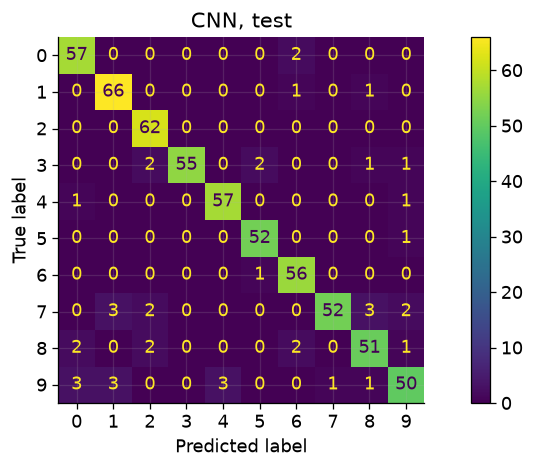

Большой stride и pooling сокращают пространственное разрешение. Это снижает вычислительную нагрузку и может удалить тонкие штрихи. Изменение padding также меняет долю краевых пикселей. Ошибки похожих цифр дополнительно усиливаются шумом.

In [3]:
rows = []
for label, kw in [
    ("standard", {}),
    ("padding0", {"padding": 0}),
    ("stride2", {"stride": 2}),
    ("average_pool", {"pool": "average"}),
]:
    seed_all()
    m = CNN(**kw)
    m, h, t = fit(m, train, val, epochs=5, lr=0.003)
    metrics, _, _ = classify(m, val)
    rows.append(
        {"configuration": label, **metrics, "seconds": t, "parameters": count_params(m)}
    )
table(rows, OUT, "geometry_experiments")
seed_all()
noisy = (torch.clamp(test[0] + 0.2 * torch.randn_like(test[0]), 0, 1), test[1])
print("CNN clean:", classify(cnn, test)[0], "noise σ=.2:", classify(cnn, noisy)[0])
errors(cnn, test, OUT)
metrics, pred, p = classify(cnn, test)
ConfusionMatrixDisplay.from_predictions(test[1], pred)
plt.title("CNN, test")
showfig("confusion", OUT)
note(
    "Большой stride и pooling сокращают пространственное разрешение. Это снижает вычислительную нагрузку и может удалить тонкие штрихи. Изменение padding также меняет долю краевых пикселей. Ошибки похожих цифр дополнительно усиливаются шумом."
)

## Вариант 11. Четыре режима и контрольный повтор

Четыре режима: без регуляризации, BatchNorm, Dropout p = 0.3, BatchNorm + Dropout. Для сравнения повторяю запуск без регуляризации с seed = 12.

,mode,batch_norm,dropout,seed,accuracy,macro_f1,seconds,parameters
0,none,False,0.0,11,0.90500,0.90174,2.04394,2698
1,BatchNorm,True,0.0,11,0.96667,0.96620,2.22805,2746
2,Dropout,False,0.3,11,0.88833,0.88594,2.34972,2698
3,both,True,0.3,11,0.95167,0.95145,2.62261,2746
4,none_seed12,False,0.0,12,0.91500,0.91397,2.41978,2698


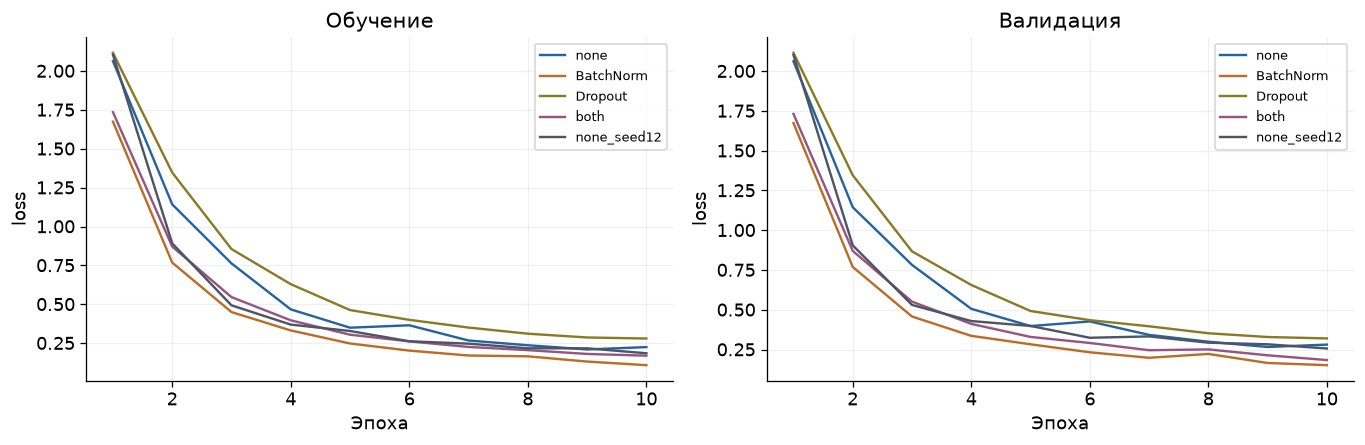

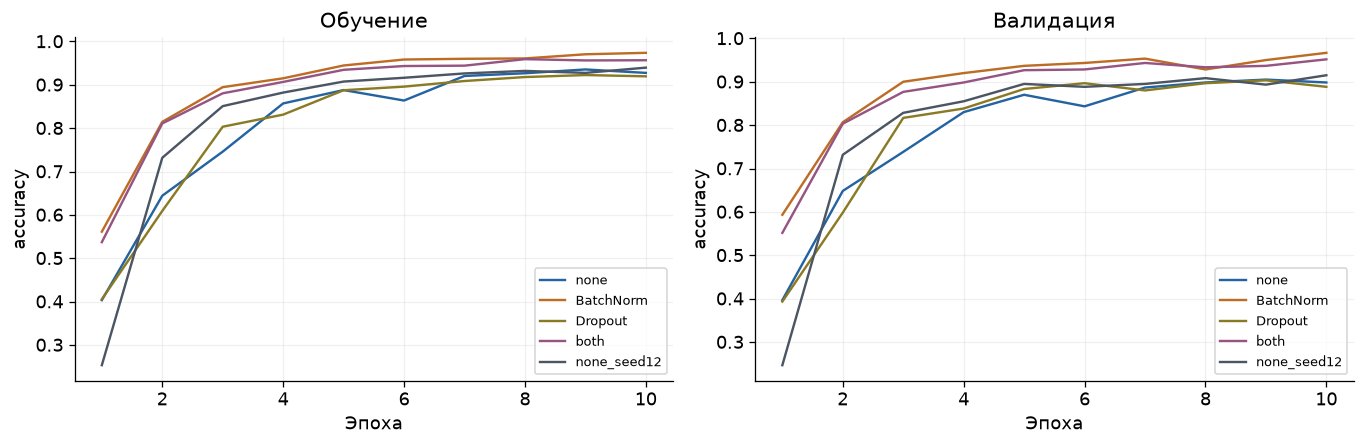

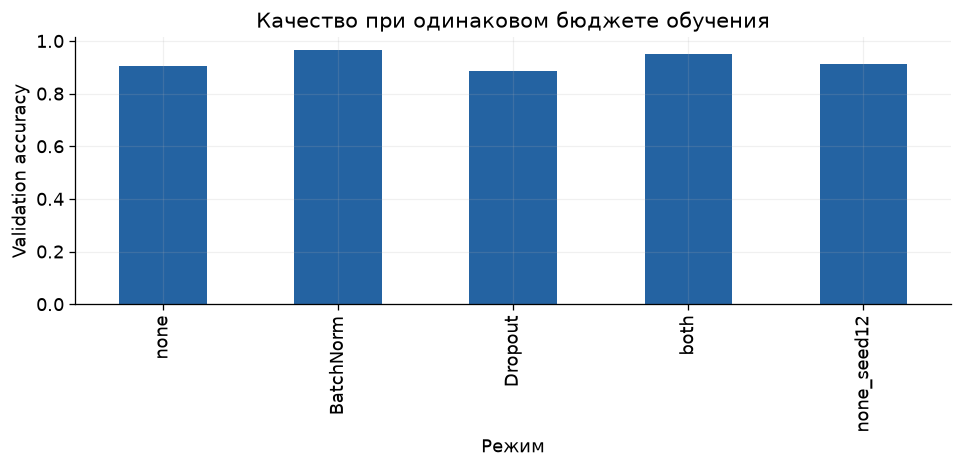

Выбор по validation: BatchNorm test: {'accuracy': 0.96, 'macro_f1': 0.9596288899379507}


,index,true,predicted,confidence,probability_margin,analysis
0,47,4,2,0.74876,0.62039,Уверенная ошибка: проверить неоднозначность пр...
1,50,7,2,0.94226,0.90342,Уверенная ошибка: проверить неоднозначность пр...
2,51,9,4,0.38536,0.11967,Ошибка при близких вероятностях классов
3,98,9,0,0.32949,0.09258,Ошибка при близких вероятностях классов
4,99,1,5,0.48259,0.18942,Ошибка при близких вероятностях классов
5,100,7,8,0.44208,0.18793,Ошибка при близких вероятностях классов
6,107,6,5,0.96517,0.94946,Уверенная ошибка: проверить неоднозначность пр...
7,115,9,7,0.32110,0.02504,Ошибка при близких вероятностях классов
8,144,4,9,0.80896,0.70950,Уверенная ошибка: проверить неоднозначность пр...
9,203,0,6,0.65578,0.50285,Уверенная ошибка: проверить неоднозначность пр...


Ошибки классификации. Большая уверенность ошибочного ответа указывает на ограничение калибровки; близкие признаки классов усложняют границу.

Выбран режим BatchNorm. BatchNorm использует batch-статистики в train и накопленные оценки в eval. Dropout применяется в train; сочетание методов не гарантирует дополнительного выигрыша. Столбец seconds показывает измеренную стоимость каждого режима. Один контрольный seed не заменяет полноценное исследование разброса.

In [4]:
rows = []
curves = {}
models = {}
for name, bn, drop, seed in [
    ("none", False, 0.0, 11),
    ("BatchNorm", True, 0.0, 11),
    ("Dropout", False, 0.3, 11),
    ("both", True, 0.3, 11),
    ("none_seed12", False, 0.0, 12),
]:
    seed_all(seed)
    m = CNN(bn=bn, dropout=drop)
    m, h, t = fit(m, train, val, epochs=10, lr=0.003, seed=seed)
    metrics, _, _ = classify(m, val)
    rows.append(
        {
            "mode": name,
            "batch_norm": bn,
            "dropout": drop,
            "seed": seed,
            **metrics,
            "seconds": t,
            "parameters": count_params(m),
        }
    )
    curves[name] = h
    models[name] = m
df = table(rows, OUT)
histories(curves, OUT, "regularization_curves")
histories(curves, OUT, "accuracy_curves", metric="accuracy")
df.set_index("mode")[["accuracy"]].plot.bar(legend=False)
plt.ylabel("Validation accuracy")
plt.xlabel("Режим")
plt.title("Качество при одинаковом бюджете обучения")
showfig("regularization_quality", OUT)
best = df.sort_values("macro_f1", ascending=False).iloc[0]["mode"]
m = models[best]
print("Выбор по validation:", best, "test:", classify(m, test)[0])
errors(m, test, OUT)
note(
    f"Выбран режим {best}. BatchNorm использует batch-статистики в train и накопленные оценки в eval. Dropout применяется в train; сочетание методов не гарантирует дополнительного выигрыша. Столбец seconds показывает измеренную стоимость каждого режима. Один контрольный seed не заменяет полноценное исследование разброса."
)

## Ответы на контрольные вопросы

1. Одно ядро может обнаруживать похожую локальную структуру в разных позициях изображения.

2. Padding и stride входят в формулу floor((n+2p−k)/s)+1; больший stride уменьшает разрешение.

3. Локальные связи и повторное использование весов сокращают число параметров по сравнению с полносвязным слоем на всех пикселях.

4. Ранние слои кодируют локальные границы и текстуры, более поздние объединяют их в более сложные структуры.

5. Пространственное укрупнение может объединить разные мелкие детали и сделать их неразличимыми.